In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report,recall_score,f1_score,confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.combine import SMOTETomek
from joblib import dump

In [2]:
df = pd.read_csv("../Datasets/synthetic_ckd_dataset_100000.csv")
df.head()

,age,gender,bmi,systolic_bp,diastolic_bp,diabetes,hypertension,serum_creatinine,blood_urea,egfr,...,hemoglobin,sodium,potassium,urine_protein,smoking,heart_disease,edema,fatigue,anemia,ckd
0,32,Male,34.1,121,69,1,1,4.20,70.0,24.2,...,8.3,133.9,4.7,0,0,0,0,0,1,1
1,75,Female,35.6,90,103,0,0,2.20,27.1,56.9,...,8.9,136.8,4.3,2,0,0,0,0,1,1
2,66,Male,29.7,170,94,0,0,1.46,17.7,77.6,...,16.9,145.4,5.8,3,0,0,0,0,0,1
3,44,Female,33.1,177,96,1,0,3.17,36.9,47.4,...,16.9,141.5,4.9,5,0,0,1,0,0,1
4,58,Female,23.2,117,91,0,0,3.78,53.5,26.1,...,9.3,132.5,5.4,4,0,0,0,0,1,1


In [3]:
df[df["ckd"] == 0]

,age,gender,bmi,systolic_bp,diastolic_bp,diabetes,hypertension,serum_creatinine,blood_urea,egfr,...,hemoglobin,sodium,potassium,urine_protein,smoking,heart_disease,edema,fatigue,anemia,ckd
11,53,Female,22.7,99,83,0,0,0.99,81.7,89.4,...,16.7,146.7,5.7,1,0,0,0,0,0,0
12,39,Female,17.0,139,71,0,0,1.93,86.6,66.8,...,14.0,138.8,3.8,1,0,0,0,0,0,0
37,41,Male,22.8,151,62,0,0,0.87,79.2,101.5,...,15.3,147.1,3.5,1,1,0,0,0,0,0
69,46,Female,34.9,99,87,0,0,1.47,95.4,83.6,...,15.3,134.3,3.6,1,1,0,0,1,0,0
88,58,Female,33.3,160,89,0,1,1.29,88.1,80.2,...,15.1,139.2,3.6,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99904,55,Female,22.2,126,92,0,0,0.65,64.3,101.9,...,16.1,136.9,6.0,0,0,0,0,0,0,0
99929,59,Male,25.6,95,77,0,0,4.00,22.0,23.2,...,16.8,131.0,3.2,1,0,0,0,1,0,0
99969,40,Female,27.6,165,89,0,0,1.00,63.7,80.6,...,12.6,142.3,5.7,1,0,0,0,0,0,0
99978,51,Female,20.7,154,80,0,0,0.86,54.8,87.9,...,12.2,133.4,4.9,5,0,0,0,1,0,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   age               100000 non-null  int64  
 1   gender            100000 non-null  object 
 2   bmi               100000 non-null  float64
 3   systolic_bp       100000 non-null  int64  
 4   diastolic_bp      100000 non-null  int64  
 5   diabetes          100000 non-null  int64  
 6   hypertension      100000 non-null  int64  
 7   serum_creatinine  100000 non-null  float64
 8   blood_urea        100000 non-null  float64
 9   egfr              100000 non-null  float64
 10  albumin           100000 non-null  int64  
 11  hemoglobin        100000 non-null  float64
 12  sodium            100000 non-null  float64
 13  potassium         100000 non-null  float64
 14  urine_protein     100000 non-null  int64  
 15  smoking           100000 non-null  int64  
 16  heart_disease     100

In [4]:
df.isna().sum()

age                 0
gender              0
bmi                 0
systolic_bp         0
diastolic_bp        0
diabetes            0
hypertension        0
serum_creatinine    0
blood_urea          0
egfr                0
albumin             0
hemoglobin          0
sodium              0
potassium           0
urine_protein       0
smoking             0
heart_disease       0
edema               0
fatigue             0
anemia              0
ckd                 0
dtype: int64

In [5]:
df.columns

Index(['age', 'gender', 'bmi', 'systolic_bp', 'diastolic_bp', 'diabetes',
       'hypertension', 'serum_creatinine', 'blood_urea', 'egfr', 'albumin',
       'hemoglobin', 'sodium', 'potassium', 'urine_protein', 'smoking',
       'heart_disease', 'edema', 'fatigue', 'anemia', 'ckd'],
      dtype='object')

In [6]:
def gender_converstion(x):
    if x == 'Male':
        return 1
    else:
        return 0
df["gender"] = df['gender'].apply(gender_converstion)

In [7]:
for col in df.columns:
        print(df[col].unique(),df[col].name)
        print()

[32 75 66 44 58 46 86 38 78 88 53 39 25 90 51 74 89 31 18 40 60 36 79 71
 45 49 64 70 63 42 41 37 73 69 48 76 67 68 30 43 54 55 35 34 84 72 85 52
 59 81 57 33 28 62 22 21 65 27 61 24 19 87 29 56 23 26 47 50 80 20 82 77
 83] age

[1 0] gender

[34.1 35.6 29.7 33.1 23.2 28.7 34.7 30.8 23.1 30.5 21.4 22.7 17.  30.4
 38.5 23.3 29.9 39.4 37.1 38.6 25.4 26.3 35.8 37.5 36.1 20.2 38.7 38.1
 36.2 33.  33.3 30.1 29.8 22.2 22.8 27.4 36.  30.9 39.3 32.1 24.1 25.8
 29.4 28.4 36.6 20.8 27.6 31.  34.2 36.8 27.8 39.6 25.2 27.5 32.3 25.7
 34.4 17.2 23.7 34.9 28.5 32.6 30.7 38.8 33.6 27.3 22.5 18.6 18.  28.9
 18.5 35.5 37.2 20.6 18.2 39.2 20.9 33.2 31.7 32.  23.9 35.2 38.9 22.
 18.8 28.8 23.6 21.1 28.6 28.  20.5 21.2 32.2 35.7 34.8 26.9 32.8 23.
 24.2 30.3 32.5 30.  29.6 39.1 18.7 19.  18.3 25.6 25.5 22.4 38.3 17.7
 25.1 31.5 21.  17.5 19.3 19.2 27.1 30.2 19.9 35.1 17.9 36.7 35.9 25.9
 32.7 36.4 24.9 31.1 20.  24.6 39.5 28.3 26.6 21.6 17.3 21.3 39.9 38.
 21.5 36.3 27.7 22.6 19.5 37.6 20.1 25.3 32.4 26.5

In [8]:
df.duplicated().sum()

np.int64(0)

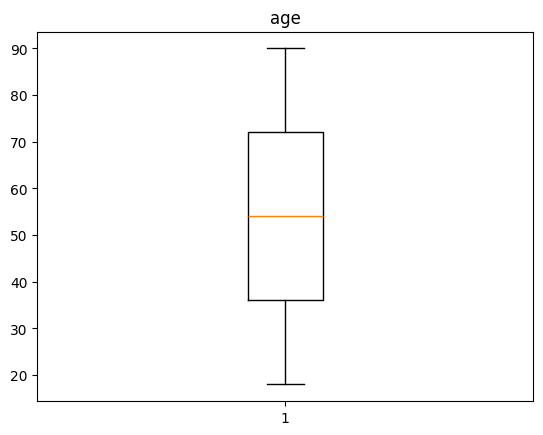

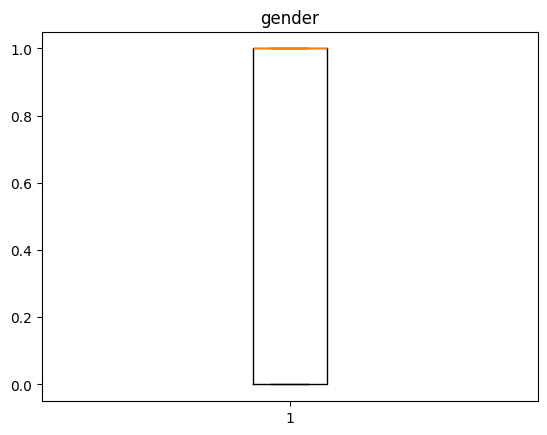

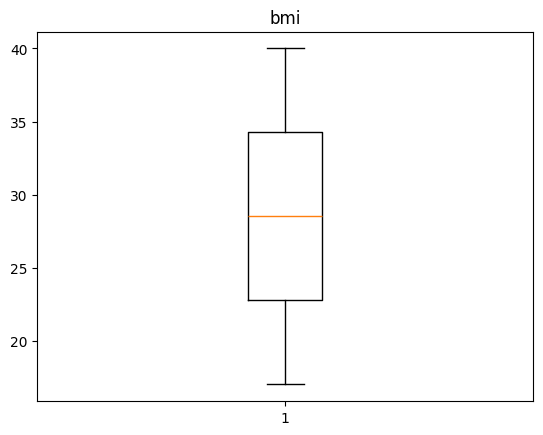

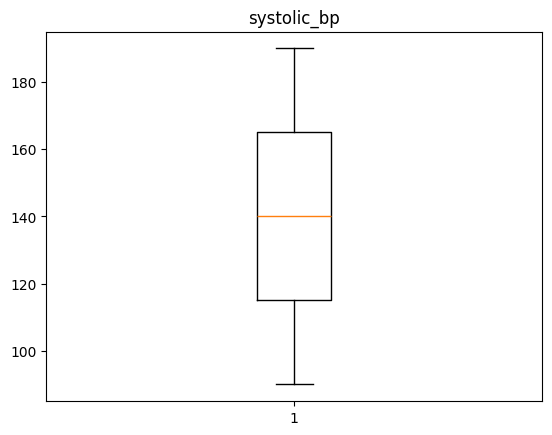

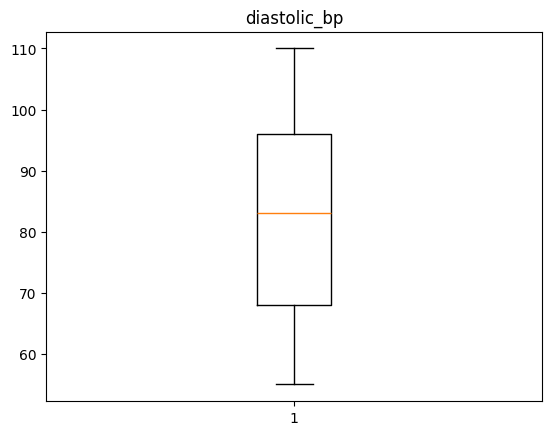

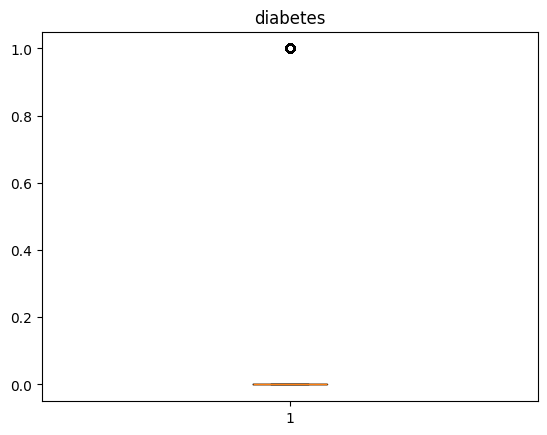

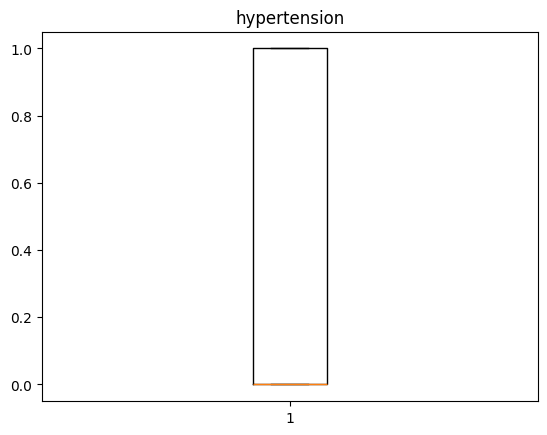

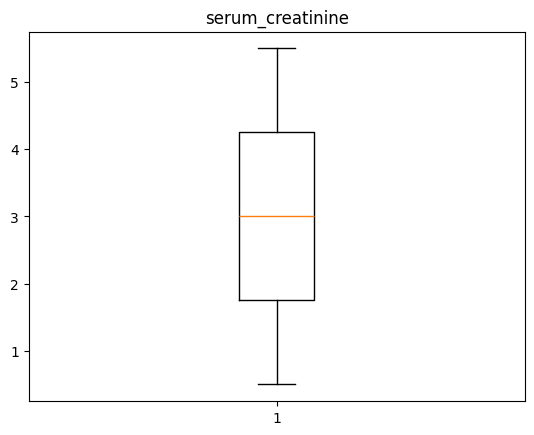

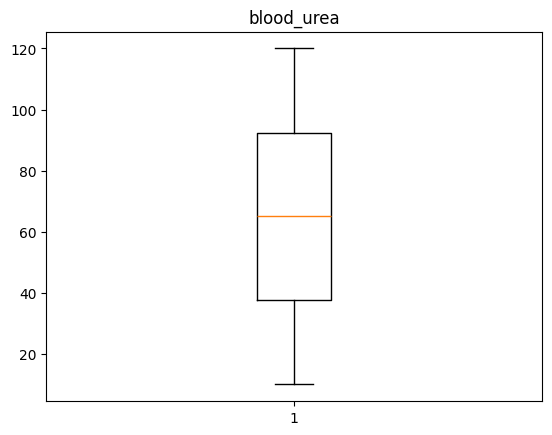

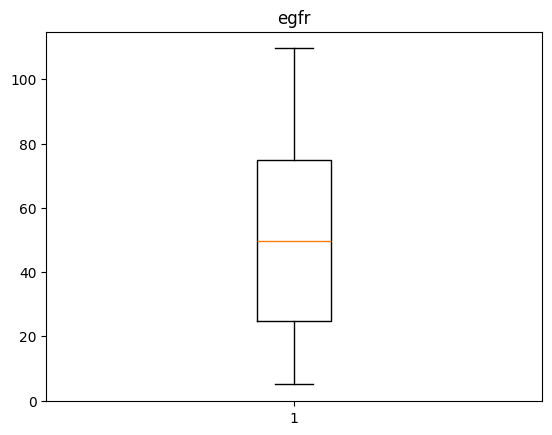

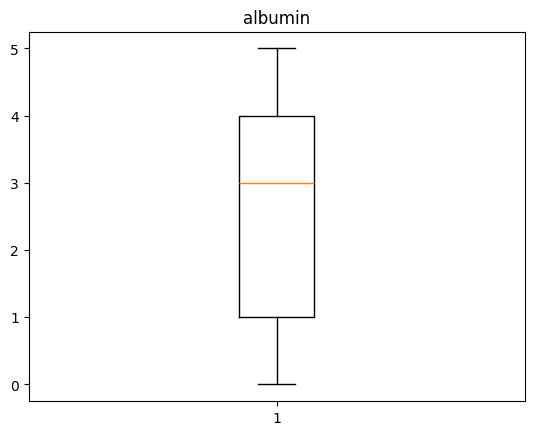

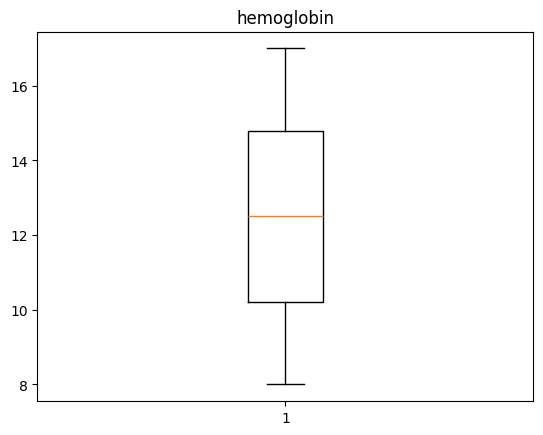

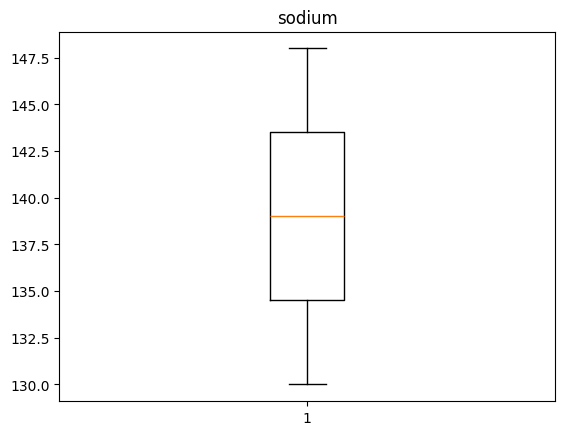

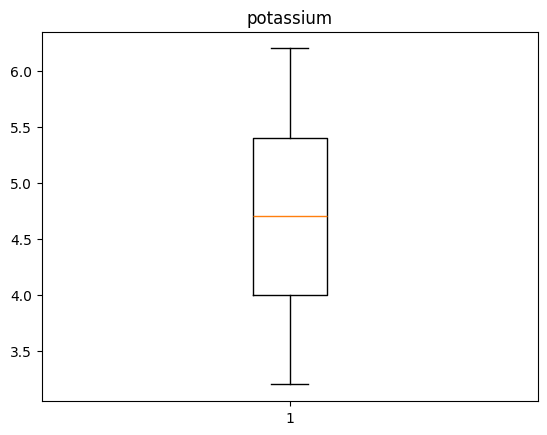

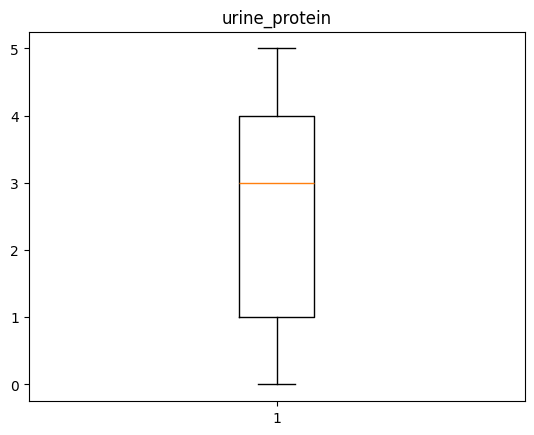

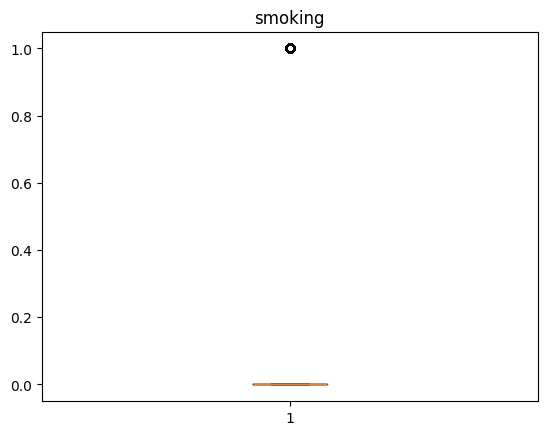

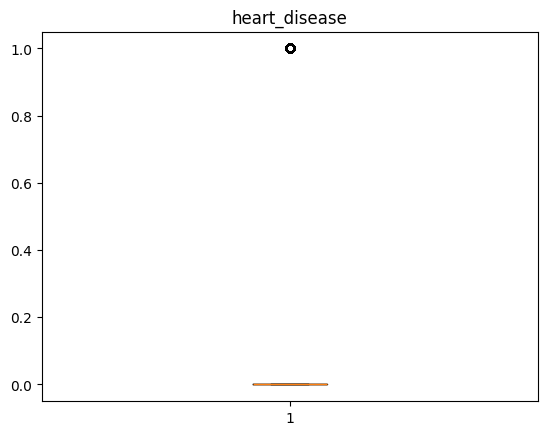

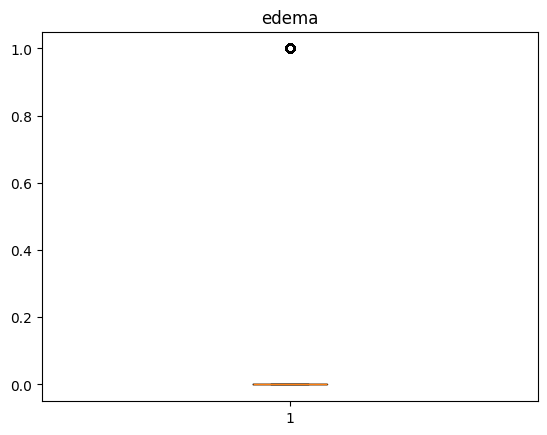

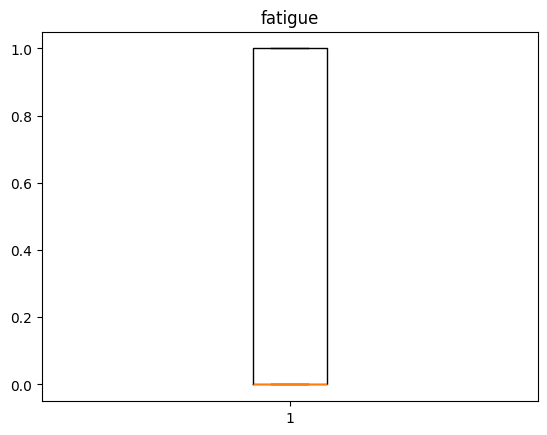

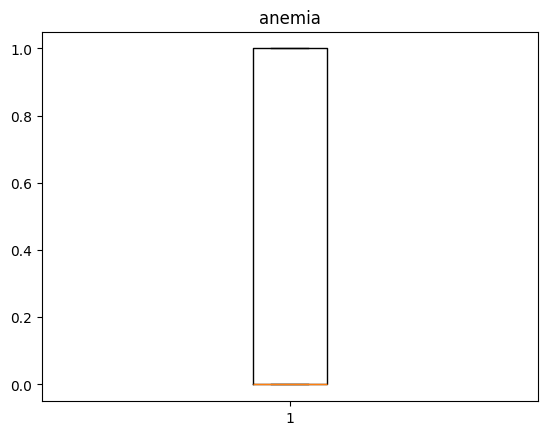

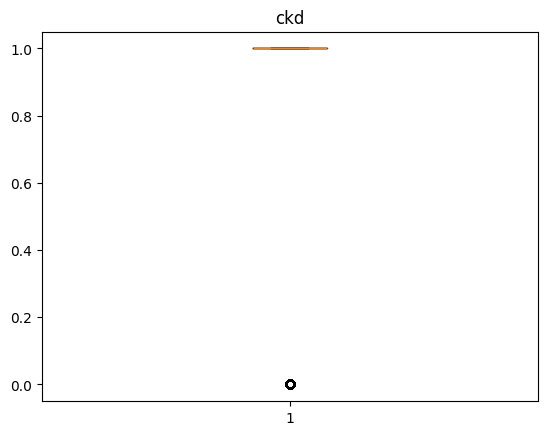

In [9]:
import matplotlib.pyplot as plt
for col in df.columns:
    plt.title(col)
    plt.boxplot(df[col])
    plt.show()

In [10]:
df.shape

(100000, 21)

In [11]:
x = df.drop(['ckd'],axis=1)
y = df['ckd']

In [12]:
(y.value_counts(normalize=True) * 100)

ckd
1    89.482
0    10.518
Name: proportion, dtype: float64

In [13]:
df.corr()['ckd'] 

age                 0.153214
gender             -0.000872
bmi                 0.001147
systolic_bp        -0.002208
diastolic_bp       -0.003550
diabetes            0.129709
hypertension        0.149188
serum_creatinine    0.348612
blood_urea          0.003791
egfr               -0.348317
albumin             0.183714
hemoglobin         -0.127934
sodium             -0.001232
potassium          -0.004087
urine_protein       0.182470
smoking            -0.002746
heart_disease       0.093861
edema               0.100902
fatigue            -0.000873
anemia              0.160599
ckd                 1.000000
Name: ckd, dtype: float64

In [14]:
x_train,x_test,y_train,y_test = train_test_split(x,y,random_state=42,stratify=y)

In [15]:
x_train.shape

(75000, 20)

In [16]:
(y_test.value_counts(normalize=True) * 100)

ckd
1    89.48
0    10.52
Name: proportion, dtype: float64

In [17]:
smt = SMOTETomek(random_state=42)

In [18]:
x_train,y_train = smt.fit_resample(x_train,y_train)

In [19]:
y_train.value_counts()

ckd
1    67046
0    67046
Name: count, dtype: int64

In [20]:
scaler = StandardScaler()

In [21]:
scaler_trian = scaler.fit_transform(x_train)
scaler_test = scaler.transform(x_test)

In [22]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(scaler_trian,y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [23]:
knn_pred = knn.predict(scaler_test)
print(classification_report(y_test,knn_pred))

              precision    recall  f1-score   support

           0       0.60      0.77      0.68      2630
           1       0.97      0.94      0.96     22370

    accuracy                           0.92     25000
   macro avg       0.79      0.86      0.82     25000
weighted avg       0.93      0.92      0.93     25000



In [24]:
tree = DecisionTreeClassifier()
tree.fit(x_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [25]:
print(classification_report(y_test,knn_pred))

              precision    recall  f1-score   support

           0       0.60      0.77      0.68      2630
           1       0.97      0.94      0.96     22370

    accuracy                           0.92     25000
   macro avg       0.79      0.86      0.82     25000
weighted avg       0.93      0.92      0.93     25000



In [26]:
tree_pred = tree.predict(x_test)
print(classification_report(y_test,tree_pred))
print(confusion_matrix(y_test,tree_pred))

              precision    recall  f1-score   support

           0       0.95      1.00      0.97      2630
           1       1.00      0.99      1.00     22370

    accuracy                           0.99     25000
   macro avg       0.97      1.00      0.99     25000
weighted avg       0.99      0.99      0.99     25000

[[ 2624     6]
 [  138 22232]]


In [27]:
tree_train = tree.predict(x_train)
print(classification_report(y_train,tree_train))
print(confusion_matrix(y_train,tree_train))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     67046
           1       1.00      1.00      1.00     67046

    accuracy                           1.00    134092
   macro avg       1.00      1.00      1.00    134092
weighted avg       1.00      1.00      1.00    134092

[[67046     0]
 [    0 67046]]


In [28]:
logistic = LogisticRegression()
logistic.fit(scaler_trian,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [29]:
log_prd = logistic.predict(scaler_test)
print(classification_report(y_test,log_prd))
print(confusion_matrix(y_test,log_prd))

              precision    recall  f1-score   support

           0       0.66      0.80      0.73      2630
           1       0.98      0.95      0.96     22370

    accuracy                           0.94     25000
   macro avg       0.82      0.88      0.84     25000
weighted avg       0.94      0.94      0.94     25000

[[ 2106   524]
 [ 1066 21304]]


In [30]:
random = RandomForestClassifier()

In [65]:
random.fit(x_train,y_train)
rand_pred = random.predict(x_test)
print(classification_report(y_test,rand_pred))
print(confusion_matrix(y_test,rand_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2630
           1       1.00      1.00      1.00     22370

    accuracy                           1.00     25000
   macro avg       0.99      1.00      1.00     25000
weighted avg       1.00      1.00      1.00     25000

[[ 2611    19]
 [   27 22343]]


In [66]:
rand_train = random.predict(x_train)
print(classification_report(y_train,rand_train))
print(confusion_matrix(y_train,rand_train))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     67046
           1       1.00      1.00      1.00     67046

    accuracy                           1.00    134092
   macro avg       1.00      1.00      1.00    134092
weighted avg       1.00      1.00      1.00    134092

[[67046     0]
 [    0 67046]]


In [62]:
xgb = XGBClassifier(n_estimators = 100,gamma = 0.1,reg_alpha = 0.1)


In [63]:
xgb.fit(x_train,y_train)
xgb_test = xgb.predict(x_test)
xgb_train = xgb.predict(x_train)

In [64]:
print(confusion_matrix(y_test,xgb_test))
print(classification_report(y_test,xgb_test))

print(confusion_matrix(y_train,xgb_train))
print(classification_report(y_train,xgb_train))

[[ 2630     0]
 [   35 22335]]
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      2630
           1       1.00      1.00      1.00     22370

    accuracy                           1.00     25000
   macro avg       0.99      1.00      1.00     25000
weighted avg       1.00      1.00      1.00     25000

[[67006    40]
 [   35 67011]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     67046
           1       1.00      1.00      1.00     67046

    accuracy                           1.00    134092
   macro avg       1.00      1.00      1.00    134092
weighted avg       1.00      1.00      1.00    134092



In [ ]:
dump(xgb,"ckd_model.joblib")

['ckd_model.joblib']